In [1]:
# ── CareFlow: portable path setup ──────────────────────────────────────
# This cell resolves paths relative to the repo root so the notebook
# works on any machine regardless of where the repo is cloned.
from pathlib import Path

# The notebook lives in  <repo>/notebook/
NOTEBOOK_DIR  = Path().resolve()          # directory Jupyter was launched from
PROJECT_ROOT  = NOTEBOOK_DIR.parent       # one level up → repo root
DATA_FILE     = PROJECT_ROOT / 'data4' / 'hospital_process_mining_event_log-1.csv'
CLEANED_DATA  = NOTEBOOK_DIR / 'cleaned_data.csv'

print('Project root :', PROJECT_ROOT)
print('Raw data     :', DATA_FILE)
print('Cleaned data :', CLEANED_DATA)


Project root : C:\Users\raagh\OneDrive\Desktop\care-flow---clinical-path-way-process-minimg
Raw data     : C:\Users\raagh\OneDrive\Desktop\care-flow---clinical-path-way-process-minimg\data4\hospital_process_mining_event_log-1.csv
Cleaned data : C:\Users\raagh\OneDrive\Desktop\care-flow---clinical-path-way-process-minimg\notebook\cleaned_data.csv


In [4]:
pip install pm4py

Note: you may need to restart the kernel to use updated packages.Collecting pm4py
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.7 MB ? eta -:--:--
   ------- -------------------------------- 0.5/2.7 MB 1.2 MB/s eta 0:00:02
   --------------- ------------------------ 1.0/2.7 MB 1.7 MB/s eta 0:00:01
   --------------- ------------------------ 1.0/2.7 MB 1.7 MB/s eta 0:00:01
   ----------------------- ---------------- 1.6/2.7 MB 1.4 MB/s eta 0:00:01
   ------------------------------- -------- 2.1/2.7 MB 1.7 MB/s eta 0:00:01
   ---------------------------------------- 2.7/2.7 MB 1.9 MB/s  0:00:02
   ---------------------------------------- 0.0/13.6 MB ? eta -:--:--
    --------------------------------------- 0.3/13


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import pm4py



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




In [6]:
df = pd.read_csv(CLEANED_DATA)

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\raagh\\OneDrive\\Desktop\\care-flow---clinical-path-way-process-minimg\\notebook\\cleaned_data.csv'

In [4]:
df

,case_id,activity,timestamp,department,resource
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk
...,...,...,...,...,...
948,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Emergency/Triage,Triage Nurse
949,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Outpatient,Doctor
950,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Outpatient,Doctor
951,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Billing,Billing Clerk


In [5]:
log = pm4py.format_dataframe(df, case_id = 'case_id', activity_key = 'activity', timestamp_key = 'timestamp')

In [6]:
log.head()

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp,@@index,@@case_index
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00+00:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00+00:00,0,0
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00+00:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00+00:00,1,0
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00+00:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00+00:00,2,0
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00+00:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00+00:00,3,0
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00+00:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00+00:00,4,0


In [7]:
start_activity = pm4py.get_start_activities(log)
end_activity = pm4py.get_end_activities(log)
print("start_activity: ",start_activity)
print("end_activity: ",end_activity)

start_activity:  {'Patient Registration': 100}
end_activity:  {'Patient Discharged': 69, 'Discharge Processed': 31}


In [8]:
activity_count = df.groupby('activity')['activity'].value_counts()

In [9]:
activity_count.sort_values(ascending=False)

activity
Patient Registration           100
Initial Triage                 100
Doctor Consultation            100
Treatment/Prescription          69
Payment Completed               69
Patient Discharged              69
Lab Results Available           60
Sample Collected                60
Lab Test Ordered                60
Doctor Reviews Results          60
Admission Decision              31
Discharge Processed             31
Bed Assigned                    31
Treatment Completed             31
Patient Transferred to Ward     31
Imaging Ordered                 14
Imaging Completed               14
Doctor Reviews Imaging          14
Repeat Doctor Consultation       9
Name: count, dtype: int64

In [10]:
dfg, first_stage, last_stage = pm4py.discover_dfg(log)

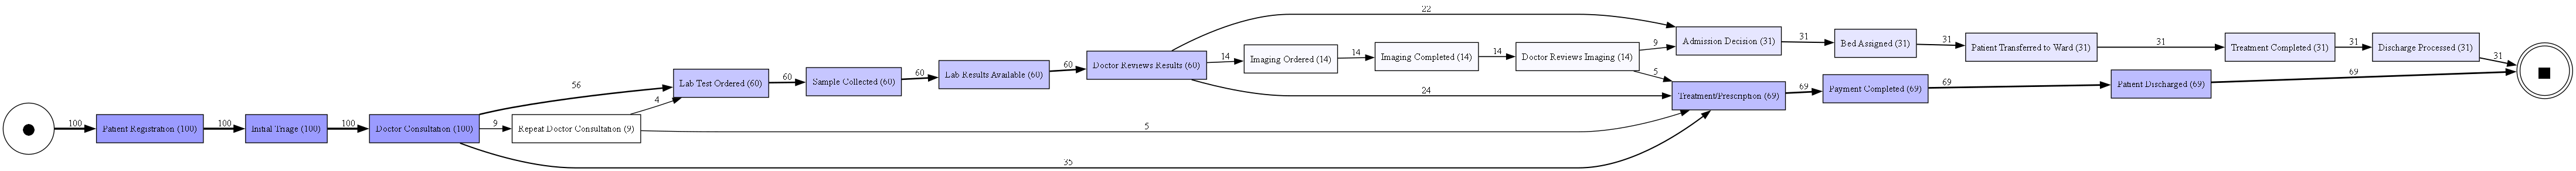

In [11]:
pm4py.view_dfg(dfg, first_stage, last_stage)

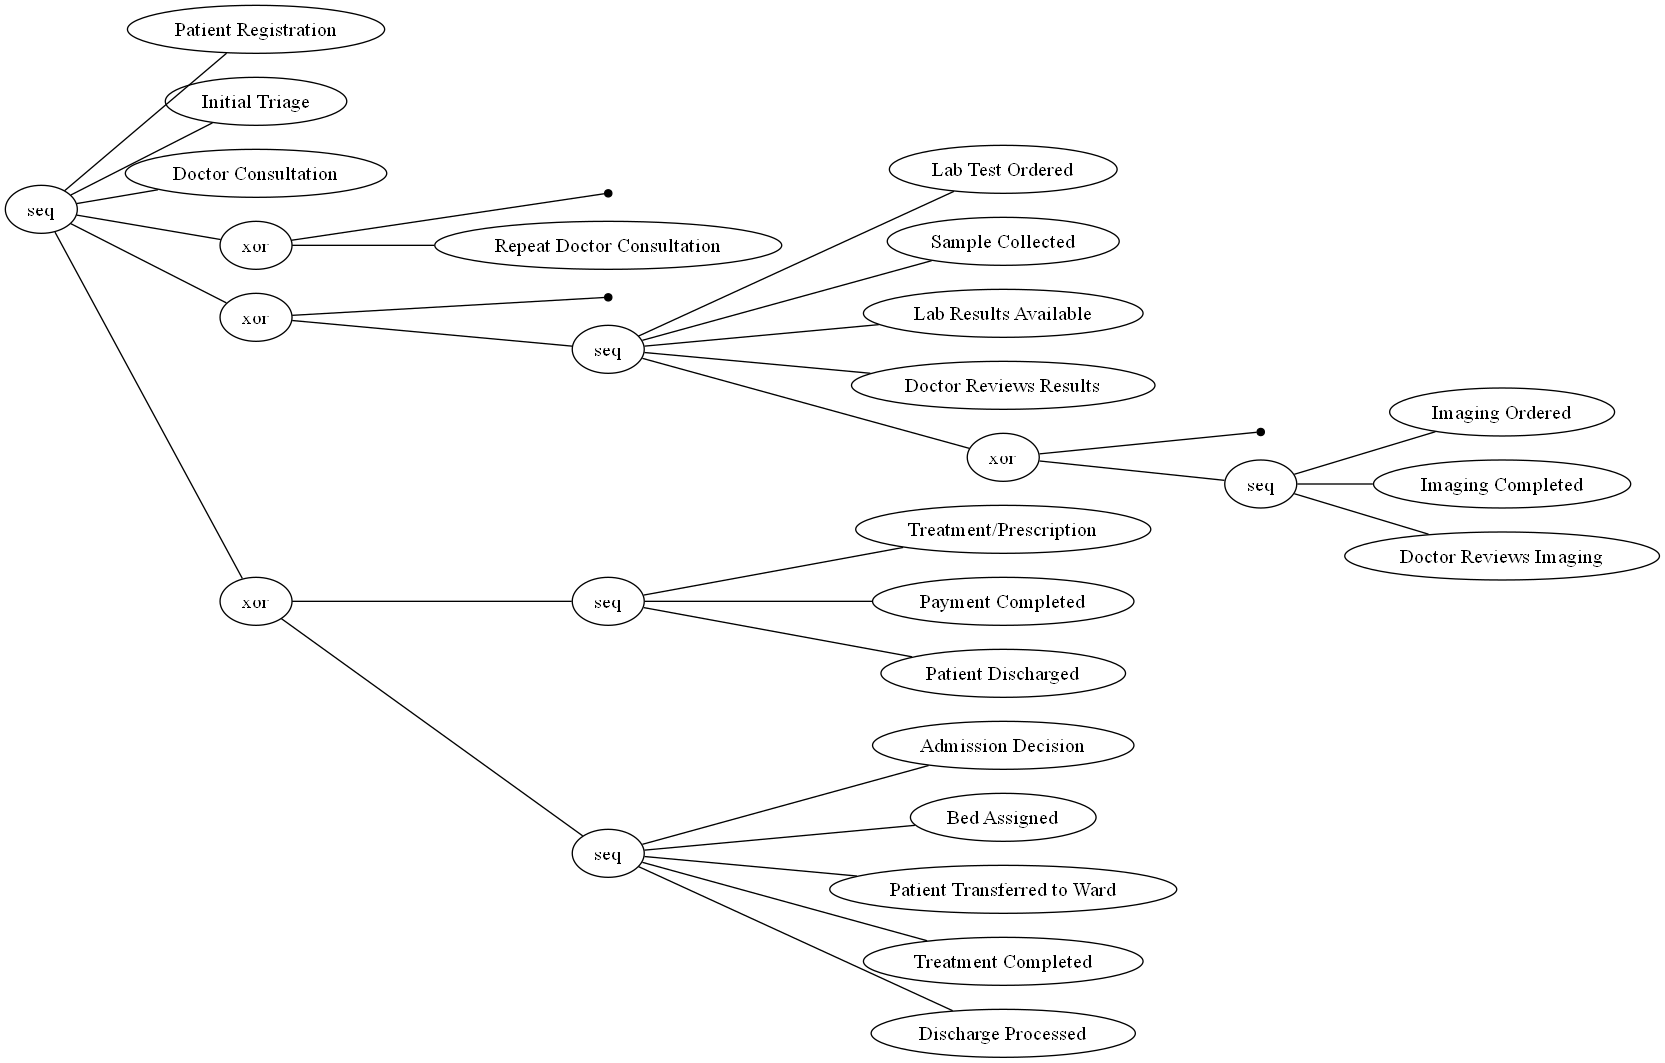

In [12]:
tree = pm4py.discover_process_tree_inductive(log)
pm4py.view_process_tree(tree)

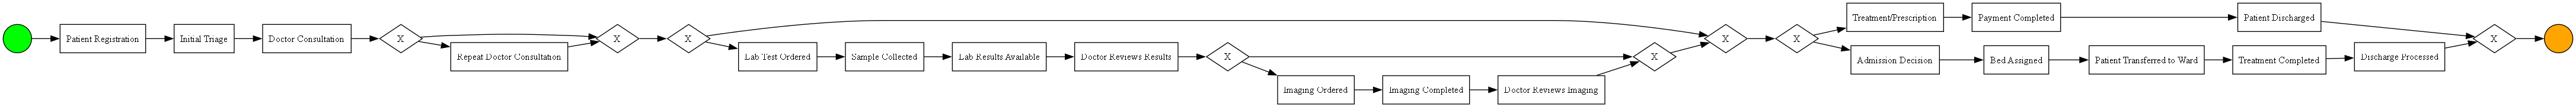

In [13]:
model = pm4py.discover_bpmn_inductive(log)
pm4py.view_bpmn(model)

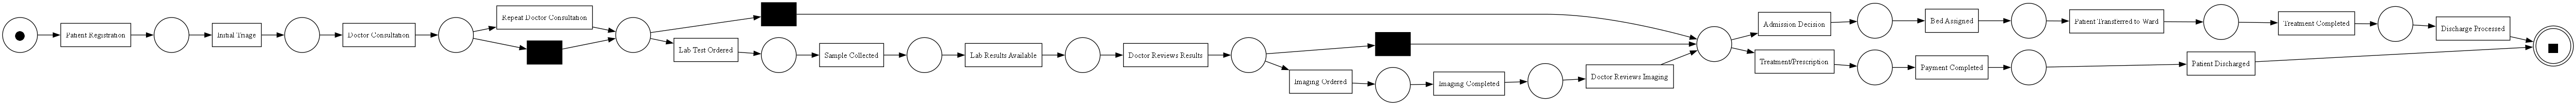

In [14]:
net, im, fm = pm4py.discover_petri_net_inductive(log)
pm4py.view_petri_net(net, im, fm)

In [15]:
df

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00
...,...,...,...,...,...,...,...,...
948,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Emergency/Triage,Triage Nurse,HOSP_0100,Initial Triage,2026-03-22 16:43:00
949,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Outpatient,Doctor,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00
950,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Outpatient,Doctor,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00
951,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Billing,Billing Clerk,HOSP_0100,Payment Completed,2026-03-22 17:12:00


In [16]:
df['next_activity'] = df.groupby('case_id')['activity'].shift(-1)

In [17]:
df

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp,next_activity
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Initial Triage
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Doctor Consultation
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Treatment/Prescription
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Payment Completed
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Patient Discharged
...,...,...,...,...,...,...,...,...,...
948,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Emergency/Triage,Triage Nurse,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Doctor Consultation
949,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Outpatient,Doctor,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Treatment/Prescription
950,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Outpatient,Doctor,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Payment Completed
951,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Billing,Billing Clerk,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Patient Discharged


In [18]:
df['next_activity_time'] = df.groupby('case_id')['timestamp'].shift(-1)

In [19]:
df.head(10)

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp,next_activity,next_activity_time
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Initial Triage,2026-03-23 09:14:00
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Doctor Consultation,2026-03-23 09:19:00
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Treatment/Prescription,2026-03-23 09:40:00
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Payment Completed,2026-03-23 09:56:00
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Patient Discharged,2026-03-23 10:00:00
5,HOSP_0001,Patient Discharged,2026-03-23 10:00:00,Outpatient,Nurse,HOSP_0001,Patient Discharged,2026-03-23 10:00:00,NaN,NaN
6,HOSP_0002,Patient Registration,2026-01-12 10:43:00,Front Desk,Registration Clerk,HOSP_0002,Patient Registration,2026-01-12 10:43:00,Initial Triage,2026-01-12 11:00:00
7,HOSP_0002,Initial Triage,2026-01-12 11:00:00,Emergency/Triage,Triage Nurse,HOSP_0002,Initial Triage,2026-01-12 11:00:00,Doctor Consultation,2026-01-12 11:21:00
8,HOSP_0002,Doctor Consultation,2026-01-12 11:21:00,Outpatient,Doctor,HOSP_0002,Doctor Consultation,2026-01-12 11:21:00,Treatment/Prescription,2026-01-12 11:32:00
9,HOSP_0002,Treatment/Prescription,2026-01-12 11:32:00,Outpatient,Doctor,HOSP_0002,Treatment/Prescription,2026-01-12 11:32:00,Payment Completed,2026-01-12 11:35:00


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   case_id             953 non-null    object
 1   activity            953 non-null    object
 2   timestamp           953 non-null    object
 3   department          953 non-null    object
 4   resource            953 non-null    object
 5   case:concept:name   953 non-null    object
 6   concept:name        953 non-null    object
 7   time:timestamp      953 non-null    object
 8   next_activity       853 non-null    object
 9   next_activity_time  853 non-null    object
dtypes: object(10)
memory usage: 74.6+ KB


In [21]:
df['next_activity_time'] = pd.to_datetime(df['next_activity_time'])

In [22]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [23]:
df['waiting_time'] = (df['next_activity_time'] - df['timestamp']).dt.total_seconds()/60

In [24]:
df

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp,next_activity,next_activity_time,waiting_time
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Initial Triage,2026-03-23 09:14:00,20.0
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Doctor Consultation,2026-03-23 09:19:00,5.0
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Treatment/Prescription,2026-03-23 09:40:00,21.0
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Payment Completed,2026-03-23 09:56:00,16.0
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Patient Discharged,2026-03-23 10:00:00,4.0
...,...,...,...,...,...,...,...,...,...,...,...
948,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Emergency/Triage,Triage Nurse,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Doctor Consultation,2026-03-22 16:47:00,4.0
949,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Outpatient,Doctor,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Treatment/Prescription,2026-03-22 16:55:00,8.0
950,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Outpatient,Doctor,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Payment Completed,2026-03-22 17:12:00,17.0
951,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Billing,Billing Clerk,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Patient Discharged,2026-03-22 17:28:00,16.0


In [25]:
more_time_taken = df.groupby('activity')['waiting_time'].agg(['max', 'mean', 'min'])

In [26]:
more_time_taken.sort_values(by=['mean'], ascending=False)

,max,mean,min
activity,,,
Doctor Reviews Imaging,25.0,17.785714,3.0
Patient Registration,25.0,15.880000,4.0
Treatment/Prescription,25.0,15.536232,3.0
Imaging Completed,25.0,15.357143,5.0
Sample Collected,25.0,15.150000,3.0
Payment Completed,25.0,14.579710,3.0
Doctor Reviews Results,25.0,14.566667,3.0
Imaging Ordered,25.0,14.285714,4.0
Treatment Completed,25.0,13.870968,4.0


In [27]:
pm4py.save_vis_dfg(dfg, first_stage, last_stage, "dfg.png")

''

In [28]:
pm4py.save_vis_petri_net(net, im, fm, "petri_net.png")

''

In [29]:
pm4py.save_vis_bpmn(model, "bpmn.png")

''

In [30]:
pm4py.save_vis_process_tree(tree, "process_tree.png")

''

In [31]:
individual_time_taken = df.groupby(['activity', 'next_activity'])['waiting_time'].agg(['mean','median','count','min','max']).sort_values(by='mean', ascending=False)

In [32]:
individual_time_taken

mean  median  \
activity                    next_activity                                    
Doctor Reviews Imaging      Treatment/Prescription       18.800000    19.0   
                            Admission Decision           17.222222    19.0   
Doctor Consultation         Repeat Doctor Consultation   16.666667    17.0   
Patient Registration        Initial Triage               15.880000    17.0   
Treatment/Prescription      Payment Completed            15.536232    16.0   
Imaging Completed           Doctor Reviews Imaging       15.357143    16.5   
Sample Collected            Lab Results Available        15.150000    16.0   
Doctor Reviews Results      Imaging Ordered              15.000000    16.0   
Repeat Doctor Consultation  Treatment/Prescription       14.600000    17.0   
Payment Completed           Patient Discharged           14.579710    15.0   
Doctor Reviews Results      Treatment/Prescription       14.458333    15.0   
                            Admission Decision           14.409091    14.0   
Doctor Consultation         Treatment/Prescription       14.314286    16.0   
Imaging Ordered             Imaging Completed            14.285714    12.5   
Treatment Completed         Discharge Processed          13.870968    14.0   
Admission Decision          Bed Assigned                 13.806452    14.0   
Patient Transferred to Ward Treatment Completed          13.516129    13.0   
Lab Test Ordered            Sample Collected             13.450000    13.0   
Lab Results Available       Doctor Reviews Results       12.766667    13.0   
Bed Assigned                Patient Transferred to Ward  12.677419    11.0   
Initial Triage              Doctor Consultation          12.410000    11.5   
Doctor Consultation         Lab Test Ordered             12.267857    12.0   
Repeat Doctor Consultation  Lab Test Ordered             10.500000     9.5   

                                                         count   min   max  
activity                    next_activity                                   
Doctor Reviews Imaging      Treatment/Prescription           5  12.0  23.0  
                            Admission Decision               9   3.0  25.0  
Doctor Consultation         Repeat Doctor Consultation       9   6.0  25.0  
Patient Registration        Initial Triage                 100   4.0  25.0  
Treatment/Prescription      Payment Completed               69   3.0  25.0  
Imaging Completed           Doctor Reviews Imaging          14   5.0  25.0  
Sample Collected            Lab Results Available           60   3.0  25.0  
Doctor Reviews Results      Imaging Ordered                 14   3.0  24.0  
Repeat Doctor Consultation  Treatment/Prescription           5   6.0  24.0  
Payment Completed           Patient Discharged              69   3.0  25.0  
Doctor Reviews Results      Treatment/Prescription          24   3.0  25.0  
                            Admission Decision              22   4.0  25.0  
Doctor Consultation         Treatment/Prescription          35   4.0  25.0  
Imaging Ordered             Imaging Completed               14   4.0  25.0  
Treatment Completed         Discharge Processed             31   4.0  25.0  
Admission Decision          Bed Assigned                    31   3.0  24.0  
Patient Transferred to Ward Treatment Completed             31   3.0  25.0  
Lab Test Ordered            Sample Collected                60   3.0  24.0  
Lab Results Available       Doctor Reviews Results          60   3.0  25.0  
Bed Assigned                Patient Transferred to Ward     31   4.0  24.0  
Initial Triage              Doctor Consultation            100   3.0  25.0  
Doctor Consultation         Lab Test Ordered                56   3.0  25.0  
Repeat Doctor Consultation  Lab Test Ordered                 4   3.0  20.0

In [33]:
admision_decision = df[df['next_activity'] == 'Admission Decision']

In [34]:
admision_decision.activity

25     Doctor Reviews Results
40     Doctor Reviews Imaging
70     Doctor Reviews Results
115    Doctor Reviews Results
127    Doctor Reviews Results
168    Doctor Reviews Results
196    Doctor Reviews Results
211    Doctor Reviews Imaging
235    Doctor Reviews Results
265    Doctor Reviews Results
297    Doctor Reviews Results
331    Doctor Reviews Results
388    Doctor Reviews Results
445    Doctor Reviews Results
466    Doctor Reviews Imaging
494    Doctor Reviews Results
509    Doctor Reviews Imaging
537    Doctor Reviews Results
572    Doctor Reviews Results
584    Doctor Reviews Results
608    Doctor Reviews Results
623    Doctor Reviews Imaging
656    Doctor Reviews Results
727    Doctor Reviews Imaging
766    Doctor Reviews Results
801    Doctor Reviews Imaging
849    Doctor Reviews Results
861    Doctor Reviews Results
873    Doctor Reviews Results
888    Doctor Reviews Imaging
931    Doctor Reviews Imaging
Name: activity, dtype: object

In [35]:
admision_decision.groupby(['activity','next_activity'])['waiting_time'].agg(
    ['count', 'mean', 'median', 'min', 'max'])

,,count,mean,median,min,max
activity,next_activity,,,,,
Doctor Reviews Imaging,Admission Decision,9,17.222222,19.0,3.0,25.0
Doctor Reviews Results,Admission Decision,22,14.409091,14.0,4.0,25.0


In [36]:
print(individual_time_taken.index.get_level_values('activity').unique())
print(individual_time_taken.index.get_level_values('next_activity').unique())

Index(['Doctor Reviews Imaging', 'Doctor Consultation', 'Patient Registration',
       'Treatment/Prescription', 'Imaging Completed', 'Sample Collected',
       'Doctor Reviews Results', 'Repeat Doctor Consultation',
       'Payment Completed', 'Imaging Ordered', 'Treatment Completed',
       'Admission Decision', 'Patient Transferred to Ward', 'Lab Test Ordered',
       'Lab Results Available', 'Bed Assigned', 'Initial Triage'],
      dtype='object', name='activity')
Index(['Treatment/Prescription', 'Admission Decision',
       'Repeat Doctor Consultation', 'Initial Triage', 'Payment Completed',
       'Doctor Reviews Imaging', 'Lab Results Available', 'Imaging Ordered',
       'Patient Discharged', 'Imaging Completed', 'Discharge Processed',
       'Bed Assigned', 'Treatment Completed', 'Sample Collected',
       'Doctor Reviews Results', 'Patient Transferred to Ward',
       'Doctor Consultation', 'Lab Test Ordered'],
      dtype='object', name='next_activity')


In [37]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
import seaborn as sns

In [42]:
import matplotlib.pyplot as plt

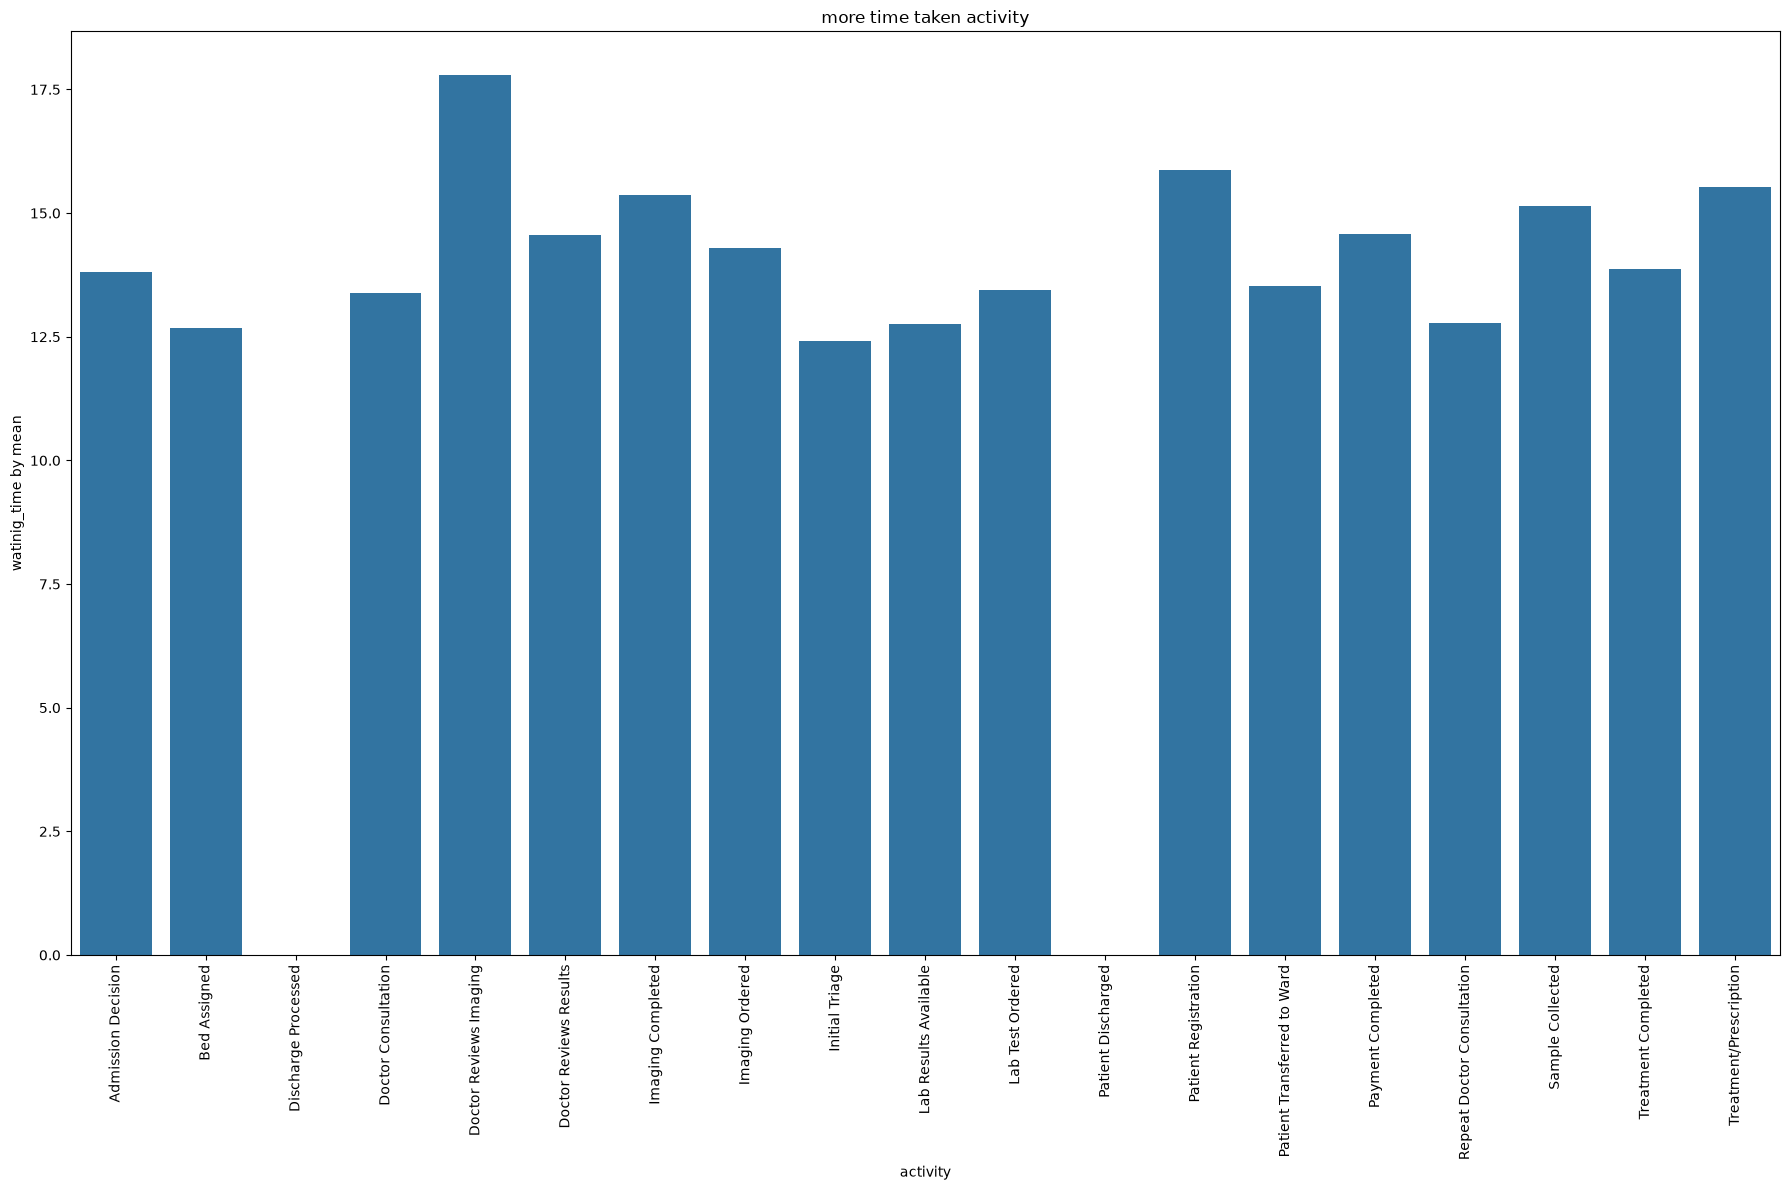

In [43]:
plt.figure(figsize=(18,12))

sns.barplot(data = more_time_taken,
            x = 'activity',
            y = 'mean')
plt.title("more time taken activity")
plt.xlabel("activity")
plt.xticks(rotation=90)
plt.ylabel("watinig_time by mean")
plt.tight_layout()
plt.savefig("more_time_taken_activity_on_overall")
plt.show()

In [48]:
top_5_bottleneck = individual_time_taken.reset_index().query("count>=10").sort_values(by="mean",ascending=False).head(5)

In [49]:
top_5_bottleneck

,activity,next_activity,mean,median,count,min,max
3,Patient Registration,Initial Triage,15.880000,17.0,100,4.0,25.0
4,Treatment/Prescription,Payment Completed,15.536232,16.0,69,3.0,25.0
5,Imaging Completed,Doctor Reviews Imaging,15.357143,16.5,14,5.0,25.0
6,Sample Collected,Lab Results Available,15.150000,16.0,60,3.0,25.0
7,Doctor Reviews Results,Imaging Ordered,15.000000,16.0,14,3.0,24.0
